In [1]:
# Checked (final)

In [2]:
import pandas as pd
import seaborn as sns
from statsmodels import robust
import matplotlib.pyplot as plt
from metricsCalculation import DataPreparationUtils as utils

In [3]:
listOf1ServerLogFolders = {
    '../data/1_server/5_clients': 5,
    '../data/1_server/10_clients': 10,
    '../data/1_server/15_clients': 15,
    '../data/1_server/20_clients': 20,
    '../data/1_server/25_clients': 25,
    '../data/1_server/30_clients': 30,
}

listOf3ServerLogFolders = {
    '../data/3_server/5_clients': 5,
    '../data/3_server/10_clients': 10,
    '../data/3_server/15_clients': 15,
    '../data/3_server/20_clients': 20,
    '../data/3_server/25_clients': 25,
    '../data/3_server/30_clients': 30,
}

listOf5ServerLogFolders = {
    '../data/5_server/5_clients': 5,
    '../data/5_server/10_clients': 10,
    '../data/5_server/15_clients': 15,
    '../data/5_server/20_clients': 20,
    '../data/5_server/25_clients': 25,
    '../data/5_server/30_clients': 30,
}

In [4]:
dfCS1Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'CS (Median)', 'MAD'])
dfCS1ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'CS'])

for (logFolder, clientNumber) in listOf1ServerLogFolders.items():
    dfClientSentLog = utils.readInClientLogsForScenario(logFolder)[0]
    dfServerConsumerLog = utils.readInServerLogsForScenario(logFolder)[1]

    dfWithCsMetric = utils.generateMetricCS(dfClientSentLog, dfServerConsumerLog)

    for i, row in dfWithCsMetric.iterrows():
        dfCS1ServerBoxPlot.loc[len(dfCS1ServerBoxPlot)] = [1, clientNumber, row['time in transit (CS)']]

    dfWithCsMetricDescribe = dfWithCsMetric.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(1, clientNumber))
    print(dfWithCsMetricDescribe['time in transit (CS)'])
    print("--------------------------------------------------------------------------")
    median = dfWithCsMetricDescribe.iat[5,2]

    dfLogMAD = robust.mad(dfWithCsMetric['time in transit (CS)'])

    dfCS1Server.loc[len(dfCS1Server)] = [clientNumber, median, dfLogMAD]

dfCS3Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'CS (Median)', 'MAD'])
dfCS3ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'CS'])

for (logFolder, clientNumber) in listOf3ServerLogFolders.items():
    dfClientSentLog = utils.readInClientLogsForScenario(logFolder)[0]
    dfServerConsumerLog = utils.readInServerLogsForScenario(logFolder)[1]

    dfWithCsMetric = utils.generateMetricCS(dfClientSentLog, dfServerConsumerLog)

    for i, row in dfWithCsMetric.iterrows():
        dfCS3ServerBoxPlot.loc[len(dfCS3ServerBoxPlot)] = [3, clientNumber, row['time in transit (CS)']]

    dfWithCsMetricDescribe = dfWithCsMetric.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(3, clientNumber))
    print(dfWithCsMetricDescribe['time in transit (CS)'])
    print("--------------------------------------------------------------------------")
    median = dfWithCsMetricDescribe.iat[5,2]

    dfLogMAD = robust.mad(dfWithCsMetric['time in transit (CS)'])

    dfCS3Server.loc[len(dfCS3Server)] = [clientNumber, median, dfLogMAD]

dfCS5Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'CS (Median)', 'MAD'])
dfCS5ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'CS'])

for (logFolder, clientNumber) in listOf5ServerLogFolders.items():
    dfClientSentLog = utils.readInClientLogsForScenario(logFolder)[0]
    dfServerConsumerLog = utils.readInServerLogsForScenario(logFolder)[1]

    dfWithCsMetric = utils.generateMetricCS(dfClientSentLog, dfServerConsumerLog)

    for i, row in dfWithCsMetric.iterrows():
        dfCS5ServerBoxPlot.loc[len(dfCS5ServerBoxPlot)] = [5, clientNumber, row['time in transit (CS)']]

    dfWithCsMetricDescribe = dfWithCsMetric.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(5, clientNumber))
    print(dfWithCsMetricDescribe['time in transit (CS)'])
    print("--------------------------------------------------------------------------")
    median = dfWithCsMetricDescribe.iat[5,2]

    dfLogMAD = robust.mad(dfWithCsMetric['time in transit (CS)'])

    dfCS5Server.loc[len(dfCS5Server)] = [clientNumber, median, dfLogMAD]

Metrics for Scenario (1 Server / 5 Clients): 
count     70.000000
mean      59.085714
std       31.696360
min       33.000000
25%       37.000000
50%       44.500000
75%       67.000000
max      166.000000
Name: time in transit (CS), dtype: float64
--------------------------------------------------------------------------
Metrics for Scenario (1 Server / 10 Clients): 
count     70.000000
mean      69.628571
std       38.079311
min       27.000000
25%       38.250000
50%       59.000000
75%       87.250000
max      170.000000
Name: time in transit (CS), dtype: float64
--------------------------------------------------------------------------
Metrics for Scenario (1 Server / 15 Clients): 
count     73.000000
mean      93.726027
std       49.670934
min       45.000000
25%       53.000000
50%       88.000000
75%      111.000000
max      348.000000
Name: time in transit (CS), dtype: float64
--------------------------------------------------------------------------
Metrics for Scenario (1 Se

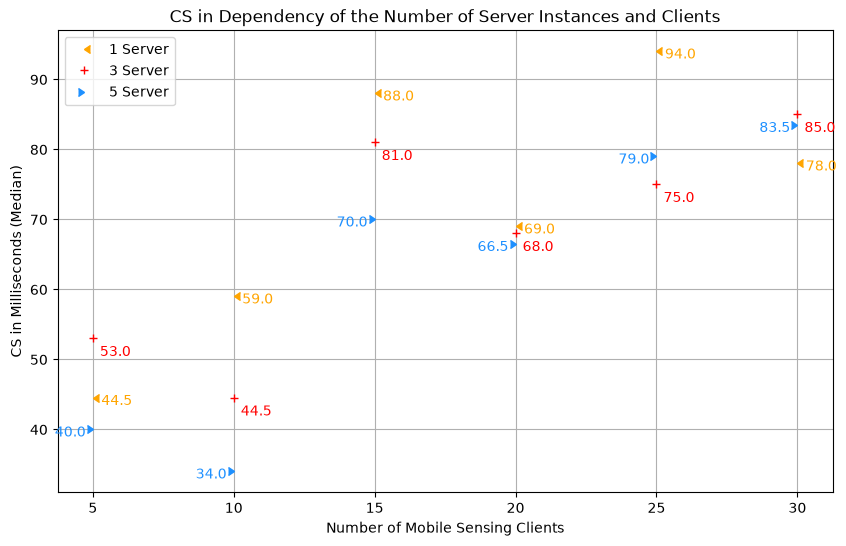

In [5]:
figure = plt.figure()

plt.plot(dfCS1Server['Number of Mobile Sensing Clients'], dfCS1Server['CS (Median)'],linestyle='', marker=4, label='1 Server', color='orange')
plt.plot(dfCS3Server['Number of Mobile Sensing Clients'], dfCS3Server['CS (Median)'],linestyle='', marker='+', label='3 Server', color= 'red')
plt.plot(dfCS5Server['Number of Mobile Sensing Clients'], dfCS5Server['CS (Median)'],linestyle='', marker=5, label='5 Server', color = 'dodgerblue')

plt.title("CS in Dependency of the Number of Server Instances and Clients")
plt.xlabel("Number of Mobile Sensing Clients")
plt.ylabel("CS in Milliseconds (Median)")

for i, row in dfCS1Server.iterrows():
    # plt.text(x=row['Number of Mobile Sensing Clients']+0.3, y=row['CS (Median)']-1, s=round(row['MAD'], 2), color='orange', horizontalalignment='left')
    plt.text(x=row['Number of Mobile Sensing Clients']+0.3, y=row['CS (Median)']-1, s=row['CS (Median)'], color='orange', horizontalalignment='left')
for i, row in dfCS3Server.iterrows():
    # plt.text(x=row['Number of Mobile Sensing Clients']+0.25, y=row['CS (Median)']-2.5, s=round(row['MAD'], 2), color='red')
    plt.text(x=row['Number of Mobile Sensing Clients']+0.25, y=row['CS (Median)']-2.5, s=row['CS (Median)'], color='red')
for i, row in dfCS5Server.iterrows():
    # plt.text(x=row['Number of Mobile Sensing Clients']-0.25, y=row['CS (Median)']-1, s=round(row['MAD'], 2), color='dodgerblue', horizontalalignment='right')
    plt.text(x=row['Number of Mobile Sensing Clients']-0.25, y=row['CS (Median)']-1, s=row['CS (Median)'], color='dodgerblue', horizontalalignment='right')

plt.grid()
plt.legend()

figure.set_figwidth(10)
figure.set_figheight(6)

plt.show()

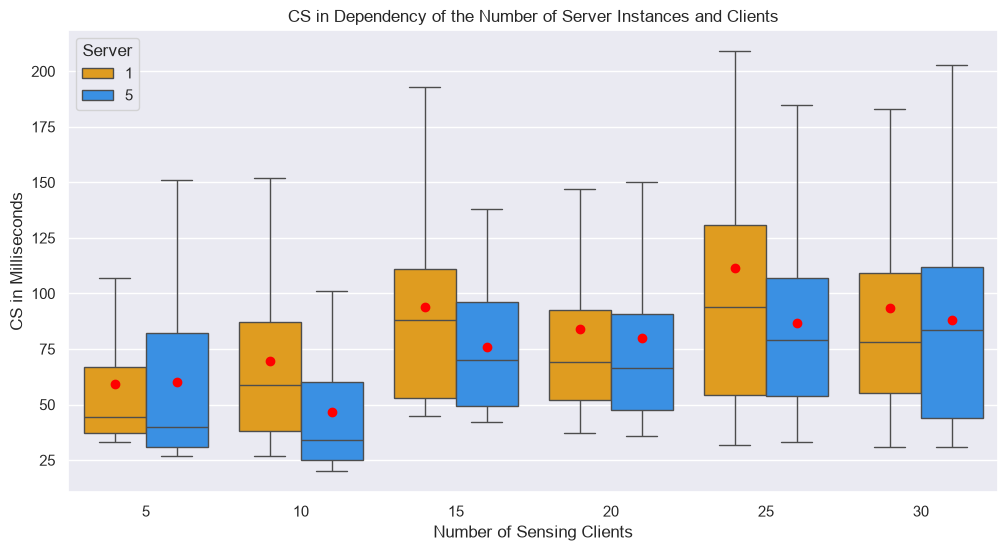

In [6]:
sns.set_theme(rc={"figure.figsize": (12,6)})

sns.boxplot(data=pd.concat([dfCS1ServerBoxPlot, dfCS5ServerBoxPlot]), showfliers=False, showmeans=True, meanprops={'marker': 'o', 'markerfacecolor': 'red', 'markeredgecolor':'red'}, hue="Server", x='Clients', y='CS', palette=['orange', 'dodgerblue']).set(title="CS in Dependency of the Number of Server Instances and Clients", xlabel="Number of Sensing Clients", ylabel="CS in Milliseconds")

plt.show()